In [1]:
# Cell 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Cell 2: Load Cleaned Dataset

df = pd.read_csv(
    "../data/processed/usgs_inventory_missing_cleaned.csv"
)

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

print("\nFirst five observations:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (8981, 37)

First five observations:


,FireName,FireYear,FireIgnitionDate,FireState,AssessmentFireID,AssessmentSegmentID,UniqueObservationID,SiteName,ObservationDate,ObservationLatitude,...,1YearStormI30,1YearStormI60,RainfallRatio15,RainfallRatio30,RainfallRatio60,HM23,dNBR/1000,KF,UpstreamArea,PreviousUSGSInventory
0,Apple,2020,20200731,CA,aed2020,aed2020_7943,Apple_2020_0001,"""Dry Creek"" east of Little San Gorgonio Creek,...",20220819.0,34.052442,...,25.75,18.77,NaN,1.56,1.81,0.2670,0.2769,0.1200,1.2603,Graber (2023)
1,Apple,2020,20200731,CA,aed2020,aed2020_9918,Apple_2020_0002,Gilman Canyon (tributary to San Gorginio River...,20221129.0,34.031818,...,25.75,18.77,1.64,1.55,1.49,0.7365,0.5839,0.1279,7.5526,Graber (2023)
2,Bear,2021,20210608,UT,ber2021,ber2021_538,Bear_2021_0001,"US Hwy 6, MP 226.7, Crandall Canyon",20230903.0,39.763579,...,17.34,10.73,2.51,2.84,2.32,0.3714,0.4991,0.2720,10.8958,Graber (2024)
3,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0001,NaN,NaN,33.888020,...,15.49,11.20,0.34,0.39,0.48,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)
4,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0002,NaN,NaN,33.888020,...,15.49,11.20,0.44,0.49,0.36,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)


In [3]:
# Cell 3: Select Features for Clustering

clustering_features = [
    "StormDuration",
    "PeakI60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea",
    "DaysSinceFire"
]

# Select clustering input features
X_cluster = df[clustering_features].copy()

# Keep Response separately for evaluating discovered clusters later
cluster_response = df["Response"].copy()

print("Clustering features selected successfully!")

print("\nNumber of features:", len(clustering_features))
print("Clustering dataset shape:", X_cluster.shape)

print("\nSelected features:")
print(clustering_features)

print("\nMissing values:")
display(X_cluster.isnull().sum().to_frame("Missing_Count"))

print("\nTarget distribution (reserved for interpretation):")
display(cluster_response.value_counts())

Clustering features selected successfully!

Number of features: 7
Clustering dataset shape: (8981, 7)

Selected features:
['StormDuration', 'PeakI60', 'HM23', 'dNBR/1000', 'KF', 'UpstreamArea', 'DaysSinceFire']

Missing values:


,Missing_Count
StormDuration,2170
PeakI60,882
HM23,448
dNBR/1000,448
KF,448
UpstreamArea,448
DaysSinceFire,0



Target distribution (reserved for interpretation):


Response
0    7841
1    1140
Name: count, dtype: int64

In [4]:
# Cell 4: Handle Missing Values Using Median Imputation

imputer = SimpleImputer(strategy="median")

X_cluster_imputed = imputer.fit_transform(X_cluster)

# Convert back to DataFrame
X_cluster_imputed = pd.DataFrame(
    X_cluster_imputed,
    columns=clustering_features,
    index=X_cluster.index
)

print("Missing values handled successfully!")

print("\nDataset shape:", X_cluster_imputed.shape)

print("\nRemaining missing values:")
print(X_cluster_imputed.isnull().sum().sum())

print("\nUpdated statistical summary:")
display(X_cluster_imputed.describe().round(3))

Missing values handled successfully!

Dataset shape: (8981, 7)

Remaining missing values:
0

Updated statistical summary:


,StormDuration,PeakI60,HM23,dNBR/1000,KF,UpstreamArea,DaysSinceFire
count,8981.000,8981.000,8981.000,8981.000,8981.000,8981.000,8981.000
mean,20.487,10.081,0.376,0.444,0.232,1.018,381.810
std,40.977,10.264,0.241,0.174,0.061,2.137,291.441
min,0.000,0.000,0.000,0.004,0.000,0.020,2.000
25%,1.400,3.300,0.180,0.321,0.190,0.069,95.000
50%,7.000,7.000,0.350,0.444,0.220,0.175,354.000
75%,21.900,12.600,0.545,0.565,0.280,0.730,686.000
max,507.900,77.600,0.990,0.997,0.564,17.346,1389.000


In [5]:
# Cell 5: Standardise Clustering Features

scaler = StandardScaler()

X_cluster_scaled = scaler.fit_transform(
    X_cluster_imputed
)

# Convert to DataFrame for easier inspection
X_cluster_scaled = pd.DataFrame(
    X_cluster_scaled,
    columns=clustering_features,
    index=X_cluster.index
)

print("Feature scaling completed successfully!")

print("\nScaled dataset shape:", X_cluster_scaled.shape)

print("\nScaled feature means:")
display(X_cluster_scaled.mean().round(3))

print("\nScaled feature standard deviations:")
display(X_cluster_scaled.std().round(3))

Feature scaling completed successfully!

Scaled dataset shape: (8981, 7)

Scaled feature means:


StormDuration   -0.0
PeakI60          0.0
HM23            -0.0
dNBR/1000        0.0
KF               0.0
UpstreamArea     0.0
DaysSinceFire    0.0
dtype: float64


Scaled feature standard deviations:


StormDuration    1.0
PeakI60          1.0
HM23             1.0
dNBR/1000        1.0
KF               1.0
UpstreamArea     1.0
DaysSinceFire    1.0
dtype: float64

In [6]:
# Cell 6: Find Optimal Number of Clusters

inertia_values = []
silhouette_values = []

k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=300
    )

    cluster_labels = kmeans.fit_predict(X_cluster_scaled)

    # Within-cluster sum of squared distances
    inertia_values.append(kmeans.inertia_)

    # Use a representative sample to reduce computation
    score = silhouette_score(
        X_cluster_scaled,
        cluster_labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_values.append(score)

    print(
        f"K = {k} | "
        f"Inertia = {kmeans.inertia_:.2f} | "
        f"Silhouette Score = {score:.4f}"
    )

print("\nCluster evaluation completed!")

K = 2 | Inertia = 53456.14 | Silhouette Score = 0.3542
K = 3 | Inertia = 44858.39 | Silhouette Score = 0.1943
K = 4 | Inertia = 39326.50 | Silhouette Score = 0.1927
K = 5 | Inertia = 34313.04 | Silhouette Score = 0.2101
K = 6 | Inertia = 30459.37 | Silhouette Score = 0.2159
K = 7 | Inertia = 28121.42 | Silhouette Score = 0.2078
K = 8 | Inertia = 26089.67 | Silhouette Score = 0.2121
K = 9 | Inertia = 24684.38 | Silhouette Score = 0.2203
K = 10 | Inertia = 23728.19 | Silhouette Score = 0.2079

Cluster evaluation completed!


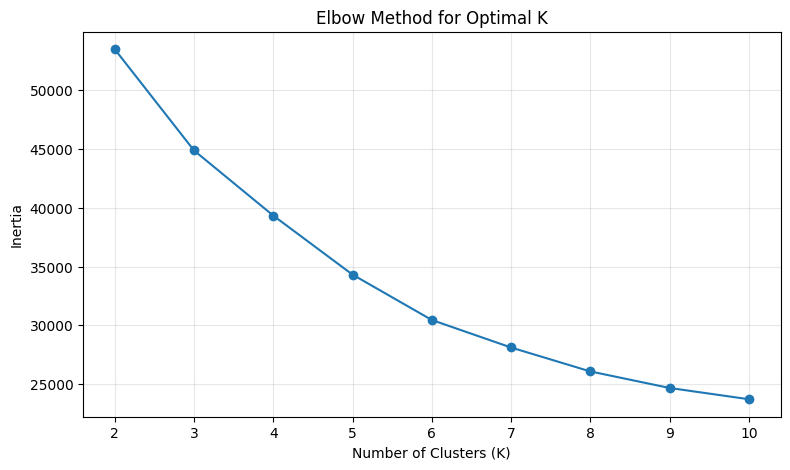

In [7]:
# Cell 7: Elbow Method Visualization

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

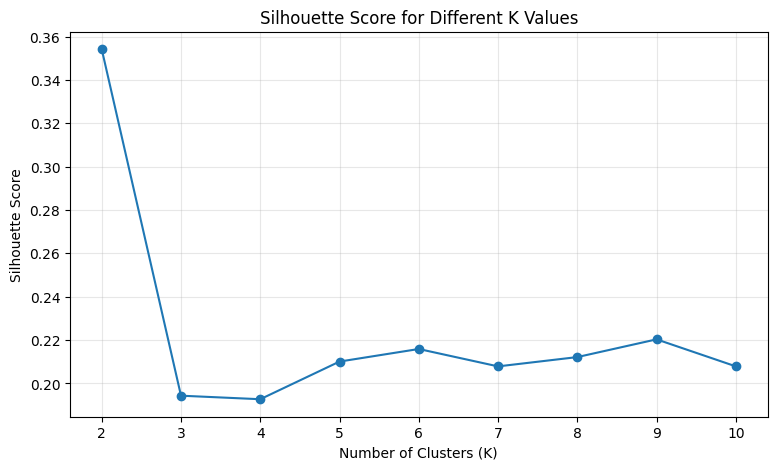

In [8]:
# Cell 8: Silhouette Score Comparison

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

In [9]:
# Cell 9: Implement K-Means Clustering

kmeans_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20,
    max_iter=300
)

# Fit model and generate cluster labels
cluster_labels = kmeans_model.fit_predict(
    X_cluster_scaled
)

# Add cluster labels to original dataset
df_clustered = df.copy()
df_clustered["Cluster"] = cluster_labels

print("K-Means clustering completed successfully!")

print("\nNumber of clusters:",
      len(np.unique(cluster_labels)))

print("\nCluster distribution:")
display(
    df_clustered["Cluster"].value_counts().sort_index()
)

K-Means clustering completed successfully!

Number of clusters: 2

Cluster distribution:


Cluster
0     757
1    8224
Name: count, dtype: int64

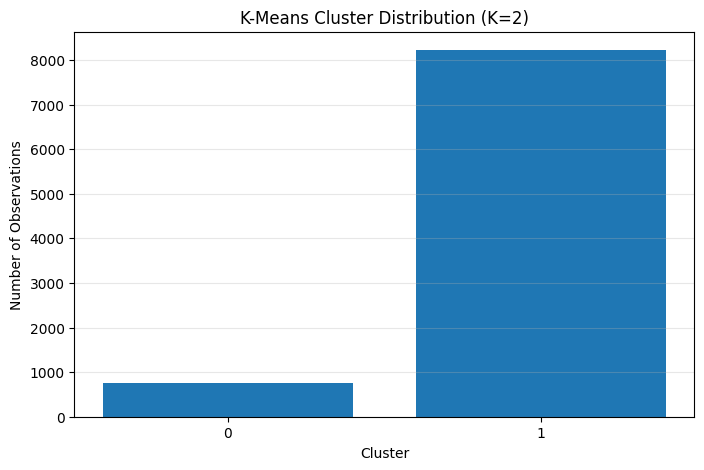

In [10]:
# Cell 10: Visualise Cluster Distribution

cluster_counts = (
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.xlabel("Cluster")
plt.ylabel("Number of Observations")
plt.title("K-Means Cluster Distribution (K=2)")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [11]:
# Cell 11: Response Distribution Across Clusters

cluster_response_table = pd.crosstab(
    df_clustered["Cluster"],
    df_clustered["Response"]
)

cluster_response_table.columns = [
    "No Debris Flow (0)",
    "Debris Flow (1)"
]

display(cluster_response_table)

# Calculate percentages
cluster_response_percentage = pd.crosstab(
    df_clustered["Cluster"],
    df_clustered["Response"],
    normalize="index"
) * 100

cluster_response_percentage.columns = [
    "No Debris Flow (%)",
    "Debris Flow (%)"
]

print("\nResponse percentage within each cluster:")

display(
    cluster_response_percentage.round(2)
)

,No Debris Flow (0),Debris Flow (1)
Cluster,,
0,711,46
1,7130,1094



Response percentage within each cluster:


,No Debris Flow (%),Debris Flow (%)
Cluster,,
0,93.92,6.08
1,86.70,13.30


In [12]:
# Cell 12: Compare Feature Profiles Across Clusters

cluster_profile = X_cluster_imputed.copy()

cluster_profile["Cluster"] = cluster_labels

# Calculate average feature values for each cluster
cluster_means = cluster_profile.groupby(
    "Cluster"
)[clustering_features].mean()

# Calculate median feature values for each cluster
cluster_medians = cluster_profile.groupby(
    "Cluster"
)[clustering_features].median()

print("AVERAGE FEATURE VALUES BY CLUSTER")
display(cluster_means.round(3))

print("\nMEDIAN FEATURE VALUES BY CLUSTER")
display(cluster_medians.round(3))

AVERAGE FEATURE VALUES BY CLUSTER


,StormDuration,PeakI60,HM23,dNBR/1000,KF,UpstreamArea,DaysSinceFire
Cluster,,,,,,,
0,59.064,6.617,0.205,0.419,0.304,7.142,527.703
1,16.936,10.400,0.392,0.446,0.225,0.454,368.381



MEDIAN FEATURE VALUES BY CLUSTER


,StormDuration,PeakI60,HM23,dNBR/1000,KF,UpstreamArea,DaysSinceFire
Cluster,,,,,,,
0,23.8,6.4,0.180,0.441,0.304,6.629,682.0
1,7.0,7.0,0.362,0.444,0.220,0.164,346.0


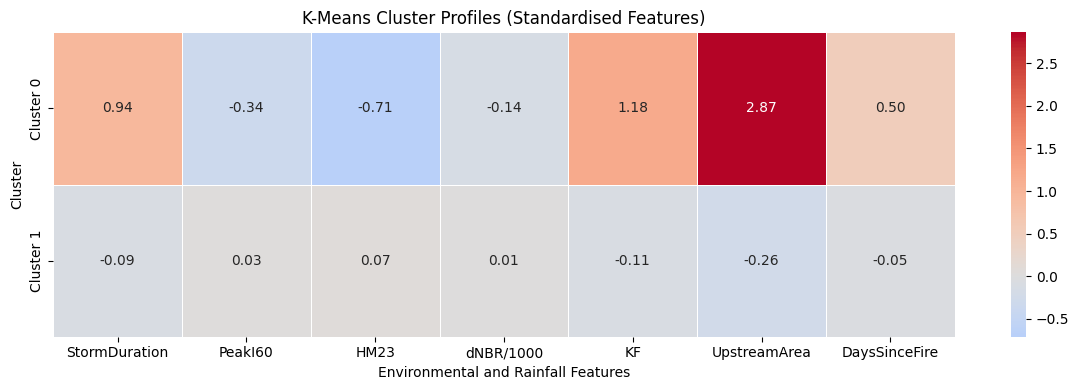

In [13]:
# Cell 13: K-Means Cluster Centre Heatmap

cluster_centres = pd.DataFrame(
    kmeans_model.cluster_centers_,
    columns=clustering_features,
    index=["Cluster 0", "Cluster 1"]
)

plt.figure(figsize=(12, 4))

sns.heatmap(
    cluster_centres,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("K-Means Cluster Profiles (Standardised Features)")
plt.xlabel("Environmental and Rainfall Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

In [14]:
# Cell 14: Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering

# Select a representative sample
hier_sample = X_cluster_scaled.sample(
    n=2000,
    random_state=42
)

# Keep corresponding response values separately
hier_response = cluster_response.loc[hier_sample.index]

# Build Agglomerative Clustering model
hierarchical_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

# Fit and generate cluster labels
hier_labels = hierarchical_model.fit_predict(
    hier_sample
)

print("Hierarchical clustering completed!")

print("Sample size:", len(hier_sample))

print("\nSilhouette Score:",
      round(silhouette_score(hier_sample, hier_labels), 4))

Hierarchical clustering completed!
Sample size: 2000

Silhouette Score: 0.3292


In [15]:
# Cell 15: Hierarchical Cluster Analysis

hier_results = pd.DataFrame({
    "Cluster": hier_labels,
    "Response": hier_response.values
}, index=hier_sample.index)

print("Cluster distribution:")
display(
    hier_results["Cluster"].value_counts().sort_index()
)

print("\nResponse distribution:")
display(
    pd.crosstab(
        hier_results["Cluster"],
        hier_results["Response"]
    )
)

print("\nResponse percentages:")
display(
    (
        pd.crosstab(
            hier_results["Cluster"],
            hier_results["Response"],
            normalize="index"
        ) * 100
    ).round(2)
)

Cluster distribution:


Cluster
0    1776
1     224
Name: count, dtype: int64


Response distribution:


Response,0,1
Cluster,,
0,1521,255
1,221,3



Response percentages:


Response,0,1
Cluster,,
0,85.64,14.36
1,98.66,1.34


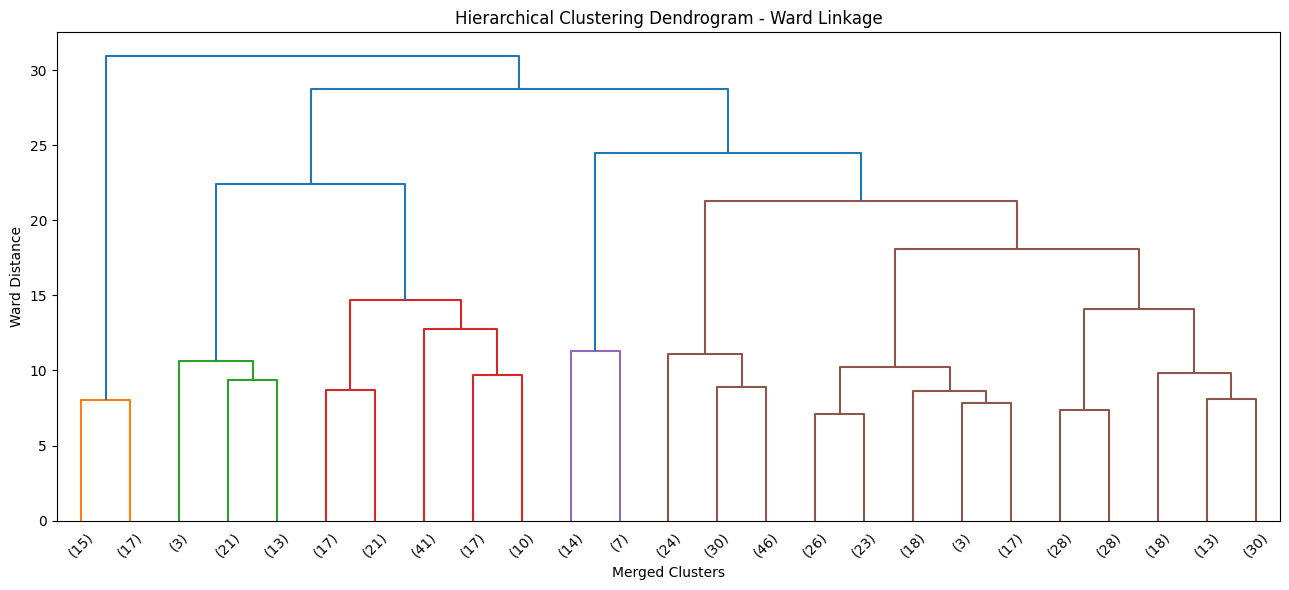

In [16]:
# Cell 16: Hierarchical Clustering Dendrogram

from scipy.cluster.hierarchy import linkage, dendrogram

# Select 500 observations for dendrogram
dendrogram_sample = hier_sample.sample(
    n=500,
    random_state=42
)

# Calculate hierarchical linkage
linkage_matrix = linkage(
    dendrogram_sample,
    method="ward"
)

# Plot dendrogram
plt.figure(figsize=(13, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=25,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram - Ward Linkage")
plt.xlabel("Merged Clusters")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

In [17]:
# Cell 17: Apply Principal Component Analysis

from sklearn.decomposition import PCA

# Fit PCA on standardised clustering features
pca_full = PCA()

X_pca_full = pca_full.fit_transform(
    X_cluster_scaled
)

# Create explained variance table
pca_variance_df = pd.DataFrame({
    "Principal_Component": [
        f"PC{i+1}" for i in range(len(clustering_features))
    ],
    "Explained_Variance_Ratio":
        pca_full.explained_variance_ratio_,
    "Explained_Variance_Percentage":
        pca_full.explained_variance_ratio_ * 100,
    "Cumulative_Variance":
        np.cumsum(pca_full.explained_variance_ratio_) * 100
})

print("PCA completed successfully!")

print("\nExplained Variance:")
display(pca_variance_df.round(4))

print("\nTotal variance explained:",
      round(pca_full.explained_variance_ratio_.sum() * 100, 2), "%")

PCA completed successfully!

Explained Variance:


,Principal_Component,Explained_Variance_Ratio,Explained_Variance_Percentage,Cumulative_Variance
0,PC1,0.2310,23.1035,23.1035
1,PC2,0.2021,20.2107,43.3142
2,PC3,0.1693,16.9321,60.2463
3,PC4,0.1242,12.4156,72.6619
4,PC5,0.1135,11.3508,84.0127
5,PC6,0.0852,8.5191,92.5317
6,PC7,0.0747,7.4683,100.0000



Total variance explained: 100.0 %


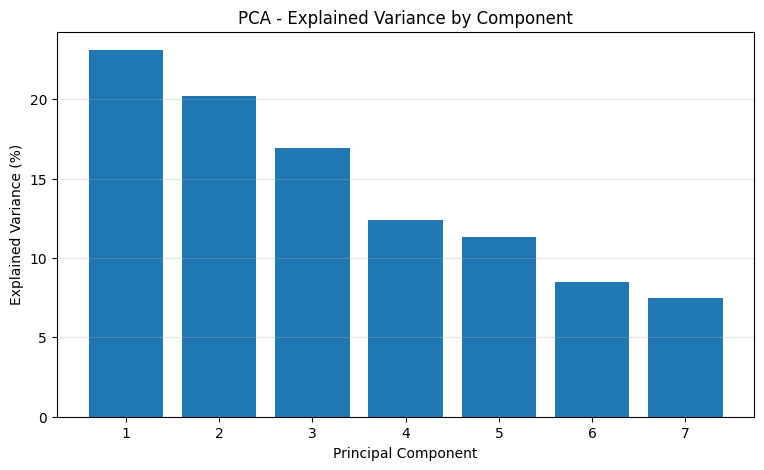

In [18]:
# Cell 18: PCA Explained Variance Visualization

components = np.arange(1, len(clustering_features) + 1)

plt.figure(figsize=(9, 5))

plt.bar(
    components,
    pca_full.explained_variance_ratio_ * 100
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA - Explained Variance by Component")

plt.xticks(components)
plt.grid(axis="y", alpha=0.3)

plt.show()

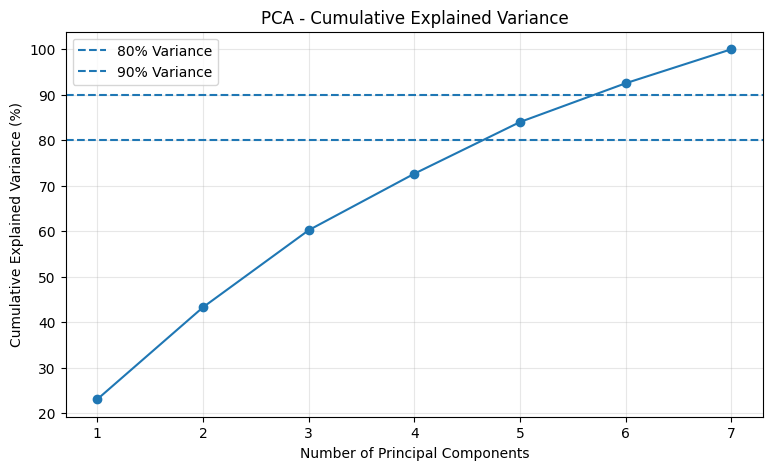

In [19]:
# Cell 19: Cumulative Explained Variance

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
) * 100

plt.figure(figsize=(9, 5))

plt.plot(
    components,
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=80,
    linestyle="--",
    label="80% Variance"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% Variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Cumulative Explained Variance")

plt.xticks(components)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

2D PCA transformation completed!
Variance retained: 43.31 %


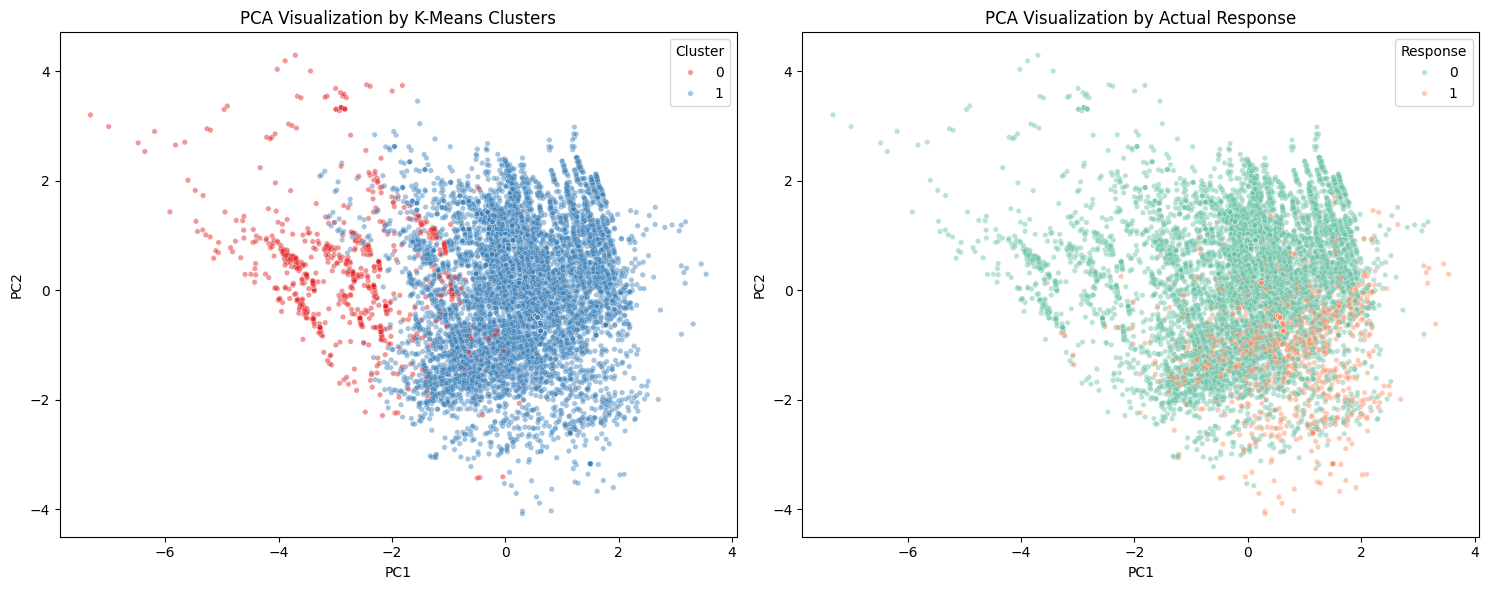

In [20]:
# Cell 20: PCA 2D Visualization

pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(
    X_cluster_scaled
)

pca_plot_df = pd.DataFrame({
    "PC1": X_pca_2d[:, 0],
    "PC2": X_pca_2d[:, 1],
    "Cluster": cluster_labels,
    "Response": cluster_response.to_numpy()
})

print("2D PCA transformation completed!")

print(
    "Variance retained:",
    round(
        pca_2d.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.45,
    s=15,
    ax=axes[0]
)

axes[0].set_title("PCA Visualization by K-Means Clusters")

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Response",
    palette="Set2",
    alpha=0.45,
    s=15,
    ax=axes[1]
)

axes[1].set_title("PCA Visualization by Actual Response")

plt.tight_layout()
plt.show()

In [21]:
# Cell 21: Reduce Dataset to Five Principal Components

pca_5 = PCA(n_components=5)

X_pca_5 = pca_5.fit_transform(
    X_cluster_scaled
)

print("Original dataset shape:", X_cluster_scaled.shape)
print("Reduced dataset shape:", X_pca_5.shape)

print(
    "\nVariance retained:",
    round(
        pca_5.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

print("\nDimensionality reduction completed!")

Original dataset shape: (8981, 7)
Reduced dataset shape: (8981, 5)

Variance retained: 84.01 %

Dimensionality reduction completed!


In [22]:
# Cell 22: Export Clustering and PCA Results

import os

os.makedirs("../outputs", exist_ok=True)

# 1. Save K-Means cluster assignments
cluster_export = df[
    ["FireName", "FireYear", "FireState",
     "UniqueObservationID", "Response"]
].copy()

cluster_export["KMeans_Cluster"] = cluster_labels

cluster_export.to_csv(
    "../outputs/kmeans_cluster_assignments.csv",
    index=False
)

# 2. Save cluster feature profiles
cluster_means.to_csv(
    "../outputs/kmeans_cluster_mean_profiles.csv"
)

cluster_medians.to_csv(
    "../outputs/kmeans_cluster_median_profiles.csv"
)

# 3. Save PCA component scores
pca_scores_df = pd.DataFrame(
    X_pca_full,
    columns=[f"PC{i+1}" for i in range(7)],
    index=df.index
)

pca_export = df[
    ["FireName", "FireState", "Response"]
].copy()

pca_export = pd.concat(
    [pca_export, pca_scores_df],
    axis=1
)

pca_export["KMeans_Cluster"] = cluster_labels

pca_export.to_csv(
    "../outputs/pca_component_scores.csv",
    index=False
)

# 4. Save PCA explained variance
pca_variance_df.to_csv(
    "../outputs/pca_explained_variance.csv",
    index=False
)

# 5. Save hierarchical clustering sample results
hier_export = df.loc[
    hier_results.index,
    ["FireName", "FireState", "Response"]
].copy()

hier_export["Hierarchical_Cluster"] = hier_labels

hier_export.to_csv(
    "../outputs/hierarchical_cluster_sample.csv",
    index=False
)

print("All clustering and PCA results exported successfully!")

print("\nSaved files:")
print("1. kmeans_cluster_assignments.csv")
print("2. kmeans_cluster_mean_profiles.csv")
print("3. kmeans_cluster_median_profiles.csv")
print("4. pca_component_scores.csv")
print("5. pca_explained_variance.csv")
print("6. hierarchical_cluster_sample.csv")

All clustering and PCA results exported successfully!

Saved files:
1. kmeans_cluster_assignments.csv
2. kmeans_cluster_mean_profiles.csv
3. kmeans_cluster_median_profiles.csv
4. pca_component_scores.csv
5. pca_explained_variance.csv
6. hierarchical_cluster_sample.csv
